# EDA: Default of Credit Card Clients (PD model)

**Goal.** Explore the UCI credit card dataset before building the probability-of-default
(PD) model, and document the decisions that feed `src/features/build_features.py`
and `src/data/validation.py`.

**Dataset.** 30 000 clients of a Taiwanese credit card issuer (April–September 2005):
demographics, six months of repayment status, bill statements and previous payments.
The target `default.payment.next.month` is `1` when the client defaults next month.

**Sections**

1. Data quality (dtypes, duplicates, missing values, undocumented category codes)
2. Target distribution (class imbalance)
3. Numeric and categorical drivers
4. Payment history — the strongest signal
5. Engineered features
6. Conclusions and modelling decisions

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Make the project importable when the notebook is executed from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import RAW_DATA_FILE, TARGET_COLUMN, BILL_COLUMNS, PAYMENT_COLUMNS, PAY_STATUS_COLUMNS
from src.data.io import load_raw_csv
from src.features.build_features import build_features, get_feature_lists

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

df = load_raw_csv(RAW_DATA_FILE)
print(f"rows: {len(df):,} | columns: {df.shape[1]}")
df.head()

rows: 30,000 | columns: 25


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 1. Data quality

The dataset has no missing values, but it is not spotless: the UCI documentation
defines `EDUCATION` as 1–4 and `MARRIAGE` as 1–3, yet the file contains codes
`0`, `5` and `6` (undocumented) plus payment statuses outside the documented
`[-2, 9]` range. All of this is handled by `clean_data`.

In [2]:
quality = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "nulls": df.isna().sum(),
        "unique": df.nunique(),
        "min": df.min(numeric_only=True),
        "max": df.max(numeric_only=True),
    }
)
display(quality)

print("duplicated client IDs:", int(df["ID"].duplicated().sum()))
print("EDUCATION value counts:")
display(df["EDUCATION"].value_counts().sort_index().to_frame("count"))
print("MARRIAGE value counts:")
display(df["MARRIAGE"].value_counts().sort_index().to_frame("count"))
print("PAY_0 range:", df["PAY_0"].min(), "-", df["PAY_0"].max())

,dtype,nulls,unique,min,max
ID,int64,0,30000,1,30000
LIMIT_BAL,int64,0,81,10000,1000000
SEX,int64,0,2,1,2
EDUCATION,int64,0,7,0,6
MARRIAGE,int64,0,4,0,3
AGE,int64,0,56,21,79
PAY_0,int64,0,11,-2,8
PAY_2,int64,0,11,-2,8
PAY_3,int64,0,11,-2,8
PAY_4,int64,0,11,-2,8


duplicated client IDs: 0
EDUCATION value counts:


,count
EDUCATION,
0,14
1,10585
2,14030
3,4917
4,123
5,280
6,51


MARRIAGE value counts:


,count
MARRIAGE,
0,54
1,13659
2,15964
3,323


PAY_0 range: -2 - 8


**Finding.** `EDUCATION` codes `0/5/6` (345 clients) and `MARRIAGE` code `0`
(54 clients) are undocumented and unknown-bucket material; they are mapped to
the "others" category (`4` and `3`) in `clean_data`. Amounts in the CSV use
scientific notation (`5e+05`), so they are re-typed to `int64` on ingestion.

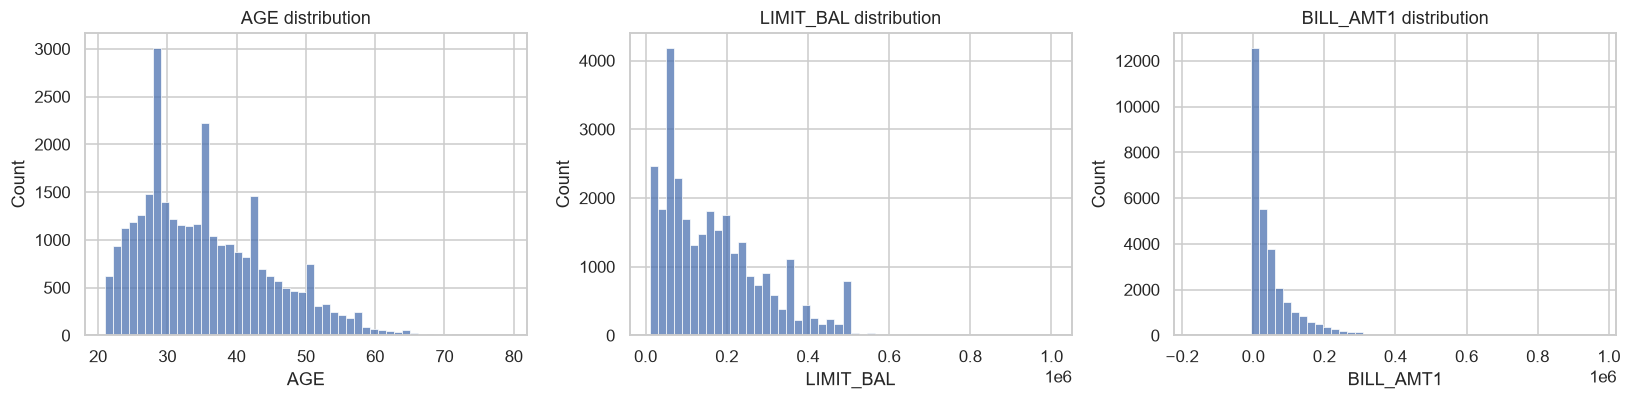

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for axis, column in zip(axes, ["AGE", "LIMIT_BAL", "BILL_AMT1"]):
    sns.histplot(df[column], bins=50, ax=axis, color="#4c72b0")
    axis.set_title(f"{column} distribution")
    axis.set_xlabel(column)
fig.tight_layout()
plt.show()

## 2. Target distribution

The classes are imbalanced — roughly **22 % default rate**. That is why the
project reports ROC-AUC, PR-AUC, KS and Precision/Recall/F1 instead of accuracy,
tunes the decision threshold, and evaluates `class_weight="balanced"` variants.

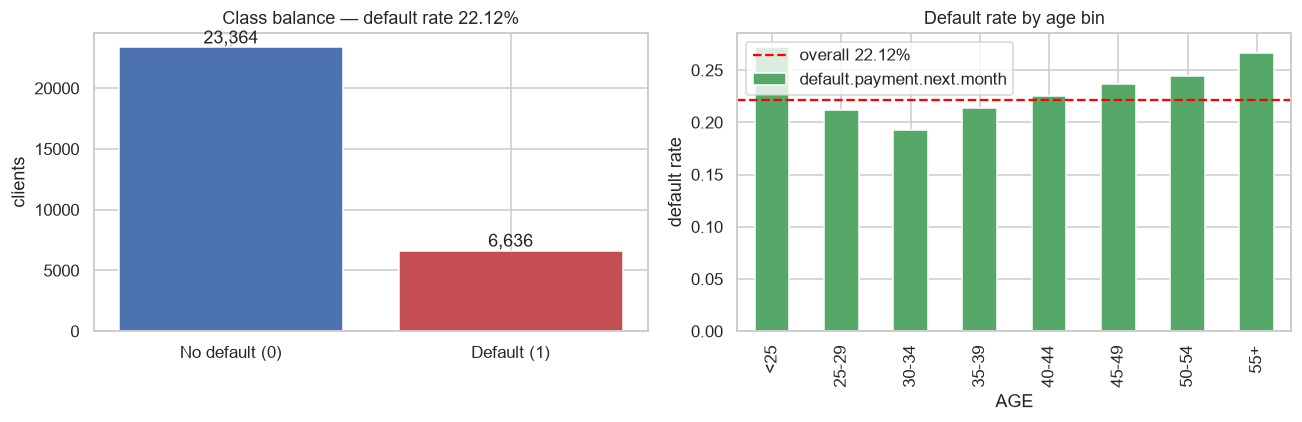

overall default rate: 22.12%


In [4]:
target_counts = df[TARGET_COLUMN].value_counts().sort_index()
default_rate = df[TARGET_COLUMN].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(["No default (0)", "Default (1)"], target_counts.values, color=["#4c72b0", "#c44e52"])
axes[0].set_title(f"Class balance — default rate {default_rate:.2%}")
axes[0].set_ylabel("clients")
for index, value in enumerate(target_counts.values):
    axes[0].text(index, value, f"{value:,}", ha="center", va="bottom")

# Default rate across the age bins used by the feature builder.
age_bins = pd.cut(df["AGE"], bins=[0, 25, 30, 35, 40, 45, 50, 55, 200], right=False,
                  labels=["<25", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54", "55+"])
by_age = df.groupby(age_bins, observed=True)[TARGET_COLUMN].mean()
by_age.plot(kind="bar", ax=axes[1], color="#55a868")
axes[1].axhline(default_rate, color="red", linestyle="--", label=f"overall {default_rate:.2%}")
axes[1].set_title("Default rate by age bin")
axes[1].set_ylabel("default rate")
axes[1].legend()
fig.tight_layout()
plt.show()

print(f"overall default rate: {default_rate:.2%}")

## 3. Categorical drivers

Sex, education and marital status show only weak differences, while the
repayment status carries most of the signal. Categorical features are therefore
one-hot encoded (low cardinality), and the numeric credit variables are
standardised inside the pipeline.

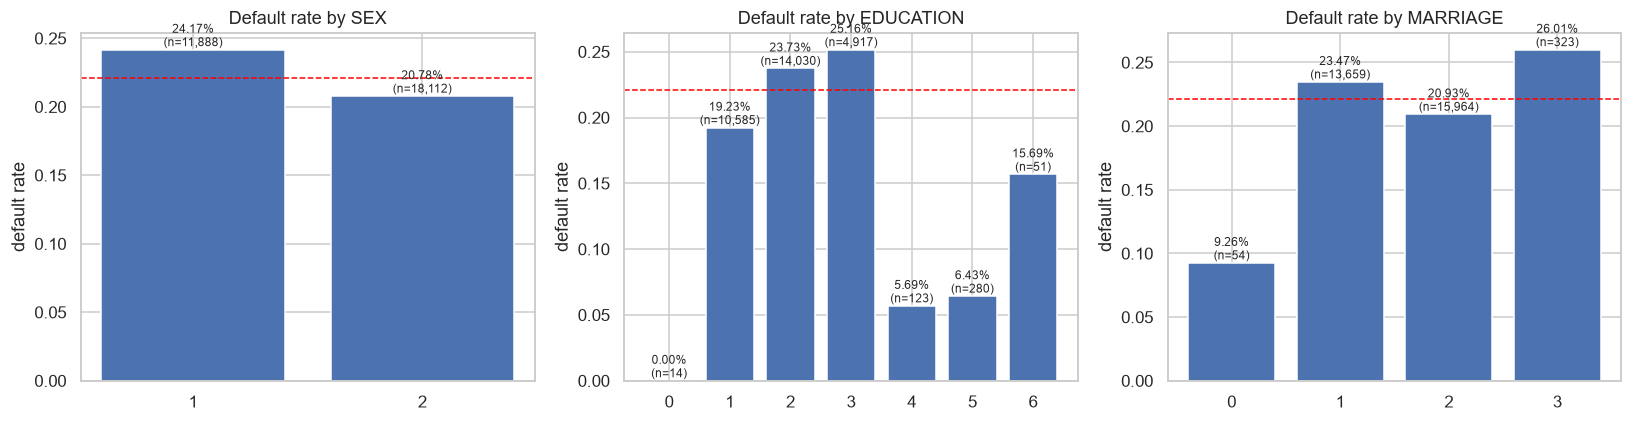

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, column in zip(axes, ["SEX", "EDUCATION", "MARRIAGE"]):
    rates = df.groupby(column)[TARGET_COLUMN].agg(["mean", "count"])
    axis.bar(rates.index.astype(str), rates["mean"], color="#4c72b0")
    axis.axhline(default_rate, color="red", linestyle="--", lw=1)
    axis.set_title(f"Default rate by {column}")
    axis.set_ylabel("default rate")
    for position, (rate, count) in enumerate(zip(rates["mean"], rates["count"])):
        axis.text(position, rate, f"{rate:.2%}\n(n={count:,})", ha="center", va="bottom", fontsize=8)
fig.tight_layout()
plt.show()

## 4. Payment history is the dominant signal

`PAY_0` (September repayment status) alone separates the classes: clients in
good standing default at ~12 %, while clients three or more months late default
at more than 60 %. This justifies the engineered features `DELINQ_COUNT`,
`MAX_DELINQ`, `SEVERE_DELINQ_COUNT` and `PAY_0_STATUS`.

,default_rate,count
PAY_0,,
-2,0.132294,2759
-1,0.167781,5686
0,0.128113,14737
1,0.339479,3688
2,0.691414,2667
3,0.757764,322
4,0.684211,76
5,0.500000,26
6,0.545455,11


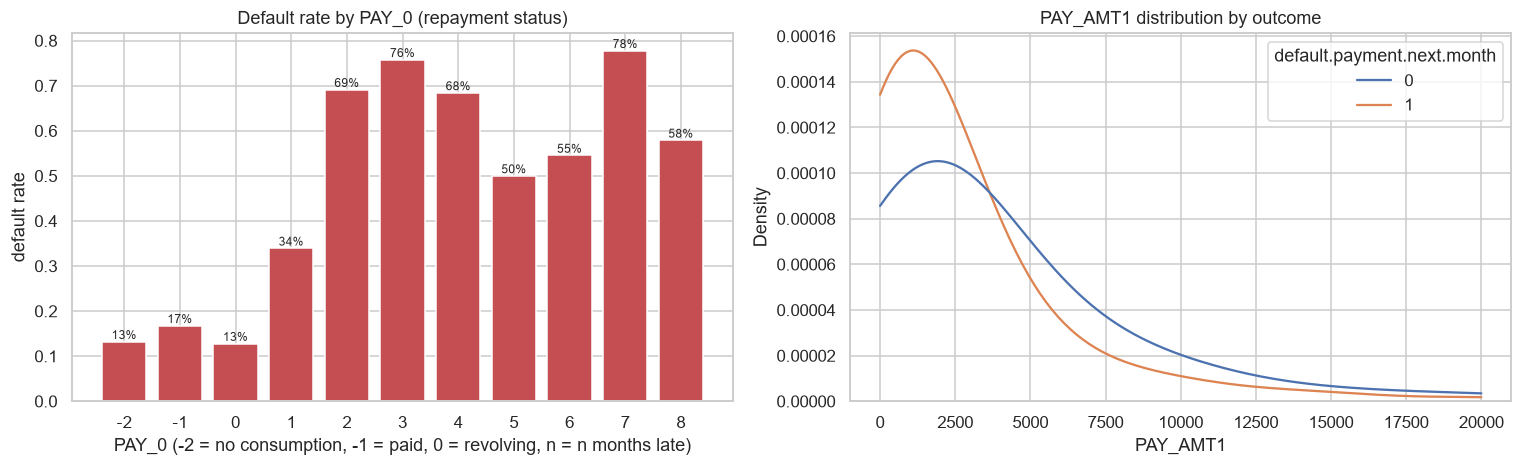

In [6]:
pay_stats = df.groupby("PAY_0")[TARGET_COLUMN].agg(["mean", "count"]).rename(columns={"mean": "default_rate"})
display(pay_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
axes[0].bar(pay_stats.index.astype(str), pay_stats["default_rate"], color="#c44e52")
axes[0].set_title("Default rate by PAY_0 (repayment status)")
axes[0].set_xlabel("PAY_0 (-2 = no consumption, -1 = paid, 0 = revolving, n = n months late)")
axes[0].set_ylabel("default rate")
for position, (rate, count) in enumerate(zip(pay_stats["default_rate"], pay_stats["count"])):
    axes[0].text(position, rate, f"{rate:.0%}", ha="center", va="bottom", fontsize=8)

sns.kdeplot(data=df, x="PAY_AMT1", hue=TARGET_COLUMN, clip=(0, 20000), common_norm=False, ax=axes[1])
axes[1].set_title("PAY_AMT1 distribution by outcome")
fig.tight_layout()
plt.show()

## 5. Correlations and engineered features

The raw numeric block is highly collinear (six monthly bill statements), which is
exactly why the project adds aggregate and trend features
(`BILL_AMT_MEAN/STD/TREND`, `CREDIT_UTILIZATION`, `PAYMENT_RATIO`).

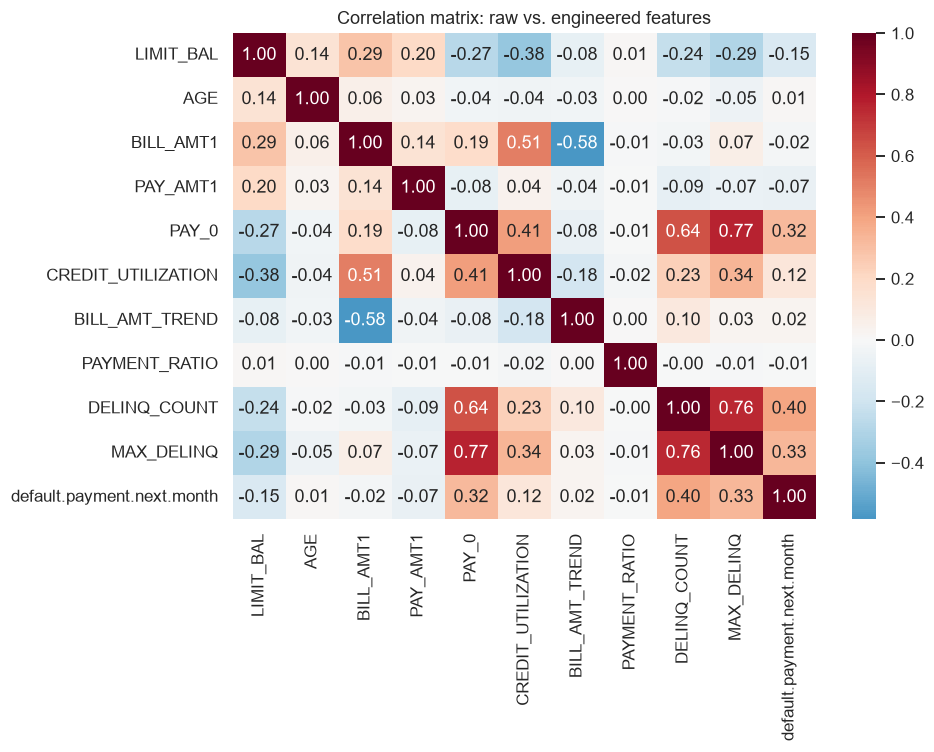

engineered feature matrix: 30,000 rows x 46 model features
numeric: 40 | categorical: 6


In [7]:
engineered = build_features(df)
numeric_features, categorical_features = get_feature_lists()

corr_columns = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "PAY_0"] + [
    "CREDIT_UTILIZATION", "BILL_AMT_TREND", "PAYMENT_RATIO", "DELINQ_COUNT", "MAX_DELINQ"
] + [TARGET_COLUMN]

fig, axis = plt.subplots(figsize=(9, 7))
sns.heatmap(
    engineered[corr_columns].corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    ax=axis,
)
axis.set_title("Correlation matrix: raw vs. engineered features")
fig.tight_layout()
plt.show()

print(f"engineered feature matrix: {len(engineered):,} rows x {len(numeric_features + categorical_features)} model features")
print("numeric:", len(numeric_features), "| categorical:", len(categorical_features))

In [8]:
comparison = (
    engineered.groupby(TARGET_COLUMN)[["CREDIT_UTILIZATION", "PAYMENT_RATIO", "DELINQ_COUNT", "BILL_AMT_TREND"]]
    .mean()
    .T
    .rename(columns={0: "no default", 1: "default"})
)
comparison["difference"] = comparison["default"] - comparison["no default"]
display(comparison.round(4))

default.payment.next.month,no default,default,difference
CREDIT_UTILIZATION,0.3514,0.4493,0.0979
PAYMENT_RATIO,25.6519,4.8013,-20.8506
DELINQ_COUNT,0.5042,1.9961,1.4919
BILL_AMT_TREND,-2749.7990,-2216.1018,533.6971


## 6. Conclusions and modelling decisions

1. **Class imbalance (~22 %)** → optimise ROC-AUC/PR-AUC, tune the decision
   threshold, report Precision/Recall/F1 at that threshold, and test
   `class_weight="balanced"` for the linear models.
2. **No missing values in the raw data**, but the pipeline still contains
   imputers: they make the service robust to partial API payloads and to future
   data deliveries.
3. **Dirty categories** (`EDUCATION` 0/5/6, `MARRIAGE` 0) are folded into
   "others" by `clean_data`; Great Expectations allows them in the raw contract
   but the model never sees undocumented groups.
4. **Payment history dominates**: `PAY_0` and the delinquency counters are the
   strongest predictors. Aggregating the six months of bill/payment history into
   means, standard deviations, trends and utilisation adds signal that a single
   month cannot provide.
5. **Feature engineering is shared** between training and serving
   (`build_features`), so the API scores raw client records without train/serve
   skew.
6. **Scaling matters for the linear model**, not for the trees; keeping
   `StandardScaler` inside the pipeline is harmless for trees and required for
   `LogisticRegression`.